# Create Easy Dataset

In this notebook, we generate a simulated "easy" EEG dataset. The simulation includes a signal for active dipoles and a background signal. The user can define a range for the number of dipoles with the active signal, and the remaining dipoles will contain only the background signal. Additionally, the user can select a range for the EEG signal-to-noise ratio (SNR), so that the variance of the background signal is adjusted to ensure the EEG SNR falls within the specified range.

I have divided this notebook into three sections:

1. Visualize the head model to be used.
2. Inspect the simulation model and determine the appropriate ranges for the number of dipoles and EEG SNR.
3. Generate the dataset.

For each section, you will need to run the '📦 Imports' and '🧠 Data' cells first. After that, the three sections are independent of each other.

## 📦 Imports

In [1]:
import mindmap as mm 
import pyvista as pv
import pywt
import numpy as np
import mne
import seaborn as sns
import pandas as pd
from pathlib import Path
import scipy as sp
import matplotlib.pyplot as plt

## 🧠 Data

In [85]:
# configuration
sub = "vepcon_sub-10"
config = mm.io.read_config("../configurations/simf.yml")

# data
data  = mm.io.read_dataset(sub, "eeg_coreg", "fwd", "sc", "parc", "cras", "white", "bem", "cst", "ctx_mask")

# features
A = mne.convert_forward_solution(data["fwd"], force_fixed=True, verbose="warning")
A = A["sol"]["data"]                                                                                    # forward matrix

vertices  = np.vstack([data["white"][0][0], data["white"][1][0]])
triangles = np.vstack([data["white"][0][1], data["white"][1][1]+len(data["white"][0][0])])
neighbors = mm.utils.find_neighbor_regions([vertices, triangles], data["parc"], data["cras"])           # region neighbors

regions = data["parc"].get_clut()["Label name"].values                                                  # region ids
pos     = mm.utils.get_src_position(data["fwd"]["src"])*1000 + data["cras"]
labels  = data["parc"].label_points(pos)                                                                # dipole labels

sfreq = data["eeg_coreg"].info["sfreq"]                                                                 # EEG sampling frequency
time  = data["eeg_coreg"].times

# parameters
duration = 1            # duration in seconds

#### Utilities

In [3]:
def spread_signal(signal, starting_roi, adjacency, r, dt):
    Xa = np.zeros((len(starting_roi), len(signal)))
    Xa[starting_roi] = signal

    i       = 1
    cum_roi = starting_roi
    test = []

    while True: 
        # compute next hop roi
        roi = (adjacency@cum_roi > 0) & (~cum_roi) 

        # check if roi is empty or wrong
        assert np.all((roi==0) | (roi==1))
        if np.all(roi==0):
            break 
        roi = roi.astype(bool)

        # update signal
        shifted_signal = np.roll(signal, i*dt)
        Xa[roi] = r**i*shifted_signal

        # update iteration
        test.append(cum_roi)
        cum_roi = cum_roi | roi
        i += 1

        if i > 20:
            raise RuntimeError("Signal still hasn't finish propagating after 20 repetitions")
        
    return Xa

## Section 1: Visualize Head Model

#### 🌟 EEG Coregistration

In [4]:
pos_elec  = mm.utils.get_ch_positions(data["eeg_coreg"])
head      = data["bem"][0]

plotter = pv.Plotter()
plotter.add_mesh(pv.PolyData(pos_elec), color="red")
plotter.add_mesh(mm.utils.surf_to_polydata(head["rr"], head["tris"]))
plotter.show()

Widget(value='<iframe src="http://localhost:36041/index.html?ui=P_0x7b82cbb1c770_0&reconnect=auto" class="pyvi…

#### 🌟 Forward Solution

In [5]:
mm.viz.plot_leadfield(data["eeg_coreg"], data["fwd"]).show()

    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]


Widget(value='<iframe src="http://localhost:36041/index.html?ui=P_0x7b81475d8110_1&reconnect=auto" class="pyvi…

#### 🌟 Connectivity

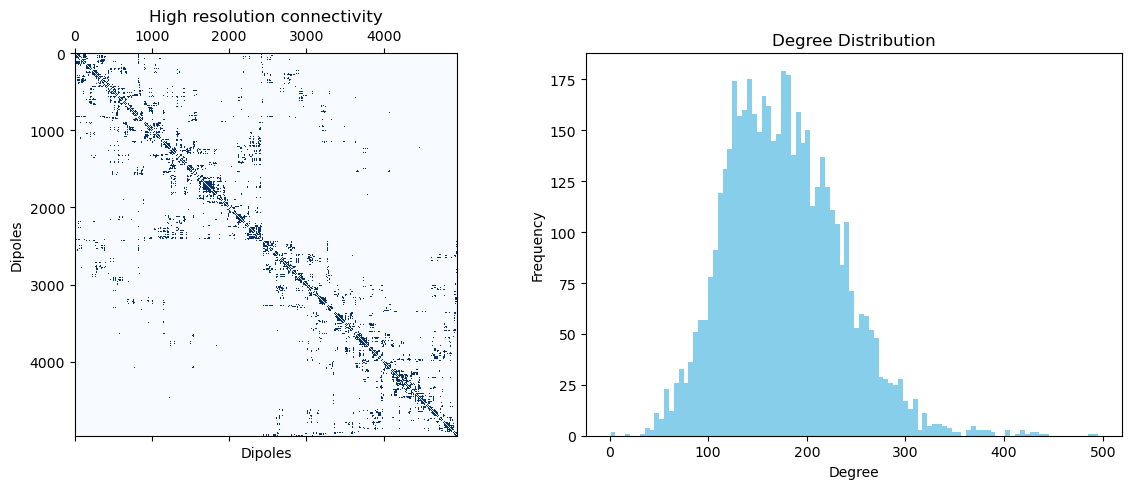

In [6]:
label_ids = data["parc"].label_points(pos, id=True)
indices   = np.argsort(label_ids)

mm.viz.plot_connectome(data["sc"][indices][:,indices], name="High resolution connectivity")

#### 🌟 Connectome spectrum

In [7]:
harmonic = data["cst"][1,:]
max_abs  = max([abs(harmonic.max()), abs(harmonic.min())])
clim     = [-max_abs, max_abs]
mm.viz.plot_brain_signal(data["fwd"]["src"], harmonic).show()

Widget(value='<iframe src="http://localhost:36041/index.html?ui=P_0x7b813826ffb0_2&reconnect=auto" class="pyvi…

## Section 2: Inspect Simulation

We found the following link between the EEG SNR of an electrode and the active/background dipoles: $$EEG_{snr} = 10\cdot \log_{10}\left( \frac{\vec a^\intercal Q^a \vec a}{\vec a^\intercal Q^b\vec a}\right)$$where $Q^a$ and $Q^b$ are the covariance matrices of the active dipoles and background dipoles respectively. $\vec a$ is the lead field vector of the electrode. <br>

In a recurrent network of linear rate neurons driven by noise, the dynamics are described by: $$\tau \dot x(t) = -x_i(t) + \sum_{j=1}^N J_{ij}x_j(t) + \mathcal E_i(t), \quad \quad i= 1, \dots, N$$where $x_i(t)$ is the firing rate of neuron $i$. $J_{ij}$ describes the recurrent interaction from neuron $j$ to $i$. $\tau$ is the time constant describing how quickly the firing rates changes in response to inputs. The network is driven by independent Gaussian noise $\mathcal E_i(t)$ with variance $\sigma^2$, that is, the expectation $\langle \mathcal E_i(t), \mathcal E_j(t+\tau)\rangle = \sigma^2 \delta_{ij}\delta{\tau}$.


It can be shown that the long time window covariance $C$ is:  $$C = \sigma^2 (I-J)^{-1}(I-J)^{-T}$$

In part 1 we test a single simulation and see if our prediciton works. Naturally, there will be some uncertainty due to the uncertainty of noise. In part 2 we simulate a high number of times to evaluate this uncertainty.

#### Part 1: Single simulation

#### 🌟 Print list of brain regions

In [8]:
print("\033[94mList of regions: \033[0m")
print(np.unique(labels))

List of regions: 
['ctx-lh-bankssts_1' 'ctx-lh-bankssts_2' 'ctx-lh-bankssts_3'
 'ctx-lh-caudalanteriorcingulate_1' 'ctx-lh-caudalanteriorcingulate_2'
 'ctx-lh-caudalanteriorcingulate_3' 'ctx-lh-caudalmiddlefrontal_1'
 'ctx-lh-caudalmiddlefrontal_2' 'ctx-lh-caudalmiddlefrontal_3'
 'ctx-lh-caudalmiddlefrontal_4' 'ctx-lh-caudalmiddlefrontal_5'
 'ctx-lh-cuneus_1' 'ctx-lh-cuneus_2' 'ctx-lh-cuneus_3' 'ctx-lh-cuneus_4'
 'ctx-lh-entorhinal_1' 'ctx-lh-frontalpole_1' 'ctx-lh-fusiform_1'
 'ctx-lh-fusiform_2' 'ctx-lh-fusiform_3' 'ctx-lh-fusiform_4'
 'ctx-lh-fusiform_5' 'ctx-lh-fusiform_6' 'ctx-lh-fusiform_7'
 'ctx-lh-fusiform_8' 'ctx-lh-inferiorparietal_1'
 'ctx-lh-inferiorparietal_10' 'ctx-lh-inferiorparietal_11'
 'ctx-lh-inferiorparietal_12' 'ctx-lh-inferiorparietal_2'
 'ctx-lh-inferiorparietal_3' 'ctx-lh-inferiorparietal_4'
 'ctx-lh-inferiorparietal_5' 'ctx-lh-inferiorparietal_6'
 'ctx-lh-inferiorparietal_7' 'ctx-lh-inferiorparietal_8'
 'ctx-lh-inferiorparietal_9' 'ctx-lh-inferiortemporal_1'
 '

#### 🛠️ <font color=violet>Select parameters for the simulation</font>
- (`starting_roi`) defines the location of the source
- `r` is the spreading factor and indicates how much the signal is sent to it's neighbors
- `eeg_snr`is the target SNR wished for

In [133]:
# background activity
scale = 1e-10                                   # brownian noise steps

# source activity
starting_roi = "ctx-lh-supramarginal_6"      # starting region 
spw          = 0.25                             # source propagation weight
spd          = 50                               # source propagation delay [ms]

# eeg properties
n_var        = 1e-7                             # white noise variance [V]
eeg_snr      = 10                               # target maximum EEG SNR

#### ⚙️ **<font color=green>Generate background activity</fon>**

In [134]:
n = data["fwd"]["nsource"]

# brownian noise
rng = np.random.default_rng()
Xb  = rng.normal(loc=0, scale=scale, size=(n, int(sfreq*duration)))
Xb  = Xb.cumsum(axis=1)


# filter between 0.1 - 1 Hz
b, a = sp.signal.butter(5, 0.5, fs=sfreq, btype="high", analog=False)
Xb   = sp.signal.lfilter(b, a, Xb)

#### 🌟 Visualize background activity

In [135]:
mm.viz.plot_brain_time_series(data["fwd"]["src"], Xb, sfreq=sfreq, cmap="bwr")

Widget(value='<iframe src="http://localhost:36041/index.html?ui=P_0x7b815ac1dd30_53&reconnect=auto" class="pyv…

#### 🌟 Visualize background spectrum

In [136]:
spectrum = data["cst"] @ Xb
mm.viz.plot_spectrum(spectrum[:, int(spectrum.shape[1]/2)])

#### **⚙️ <font color=green>Generate EEG noise activity</font>**

Text(0, 0.5, 'Voltage [uV]')

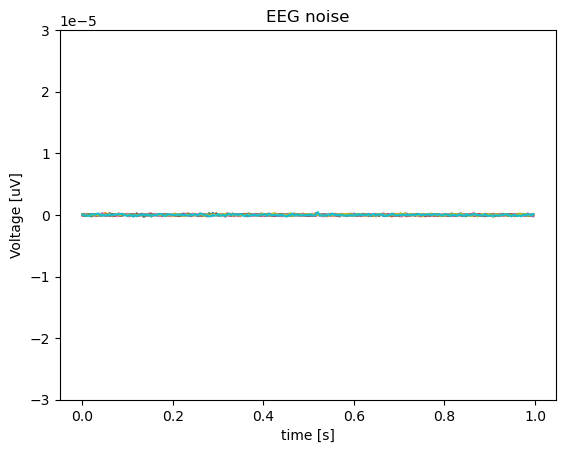

In [137]:
time  = np.arange(int(sfreq*duration))/sfreq
noise = rng.normal(loc=0, scale=n_var, size=(data["eeg_coreg"].info["nchan"], int(sfreq*duration)))

for s in noise[:10]:
    sns.lineplot(x=time, y=s)

plt.title("EEG noise")
plt.xlabel("time [s]")
plt.ylim([-30e-6, 30e-6])
plt.ylabel("Voltage [uV]")

#### ⚙️ **<font color=green>Generate source activity</font>**

In [138]:
roi_mask = np.isin(labels, starting_roi)
shift    = int(spd/1000*sfreq)

# generate spreading source
wavelet        = pywt.ContinuousWavelet("mexh")
[signal, _] = wavelet.wavefun(level=5, length=int(sfreq*duration))

Xs = spread_signal(signal, roi_mask, data["sc"], spw, shift)*1e-8

# EEG average powers
Ps   = mm.utils.avg_power(A@Xs)             # average power of source activity
Pn   = mm.utils.avg_power(A@Xb + noise)     # average power of noise
idx  = np.argmax(Ps)                        # electrode with highest source power

# scale signal to obtain target EEG SNR
scale = 10**(eeg_snr/10) * Pn[idx] / Ps[idx]
Xs    = Xs * np.sqrt(scale)

#### 🌟 Visualize source activity

In [139]:
mm.viz.plot_brain_time_series(data["fwd"]["src"], Xs, sfreq=sfreq, cmap="bwr")

Widget(value='<iframe src="http://localhost:36041/index.html?ui=P_0x7b815e55bbc0_55&reconnect=auto" class="pyv…

#### 🌟 Visualize source spectrum

In [140]:
spectrum = data["cst"] @ Xs
mm.viz.plot_spectrum(spectrum[:, int(spectrum.shape[1]/2)])

#### ⚙️ **<font color=green>Generate ground truth and EEG</font>**

In [141]:
# create ground truth
brain_activity = np.zeros((len(roi_mask),int(sfreq*duration)))
brain_activity = Xs + Xb 

vertices       = [data["fwd"]["src"][0]["vertno"], data["fwd"]["src"][1]["vertno"]]
brain_activity = mne.SourceEstimate(brain_activity, vertices, tmin=0, tstep=1/sfreq, subject=sub)

# Generate EEGs
eeg = mne.apply_forward(data["fwd"], brain_activity, data["eeg_coreg"].info, verbose="warning")
eeg.data += noise

#### 🌟 Visualize dipole signals

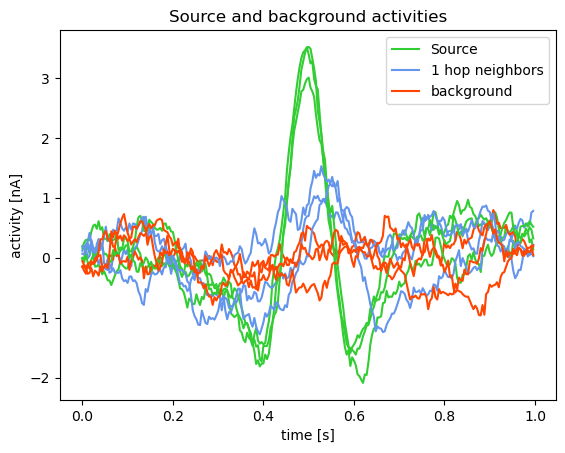

In [142]:
ab_snr = mm.utils.compute_snr(Xs[0,:], Xb[0,:])         # snr between one active dipole and one active dipole
hop2   = (data["sc"]@roi_mask > 0) & (~roi_mask)

plt.figure()
plt.plot(time, brain_activity.data[roi_mask][0]*1e9, color="limegreen", label="Source")
plt.plot(time, brain_activity.data[hop2][0]*1e9, color="cornflowerblue", label="1 hop neighbors")
plt.plot(time, brain_activity.data[~roi_mask][0]*1e9, color="orangered", label="background")
plt.legend()

plt.plot(time, brain_activity.data[roi_mask][1:3].T*1e9, color="limegreen")
plt.plot(time, brain_activity.data[hop2][1:3].T*1e9, color="cornflowerblue")
plt.plot(time, brain_activity.data[~roi_mask][1:3].T*1e9, color="orangered")

plt.title(f"Source and background activities")
plt.xlabel("time [s]")
plt.ylabel("activity [nA]")
plt.show()

#### 🌟 Visualize ground truth

In [143]:
source_snr = mm.utils.compute_snr(np.sum(Xs, axis=0), np.sum(Xb, axis=0))

print(f"Source SNR: {source_snr[0]:.3}")
mm.viz.plot_brain_time_series(data["fwd"]["src"], brain_activity.data, sfreq=sfreq, cmap="bwr")

Source SNR: 15.4


Widget(value='<iframe src="http://localhost:36041/index.html?ui=P_0x7b815afe78c0_57&reconnect=auto" class="pyv…

#### 🌟 Visualize ground truth spectrum

In [144]:
spectrum = data["cst"] @ brain_activity.data
mm.viz.plot_spectrum(spectrum[:, int(spectrum.shape[1]/2)])

#### 🌟 Visualize EEG

Maximum EEG SNR: 12.5
Average EEG snr: -1.92


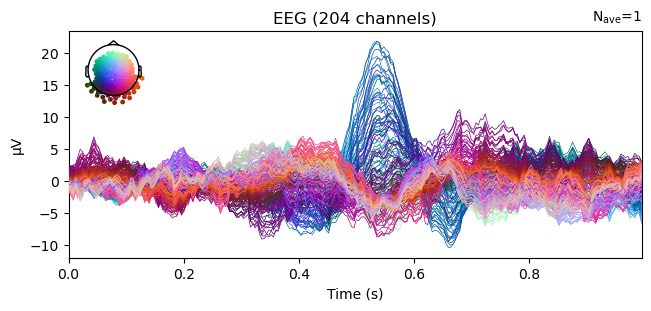

In [145]:
snr  = 10*np.log10(mm.utils.avg_power(A@Xs) / mm.utils.avg_power(A@Xb + noise))
avg  = np.mean(snr)
maxi = np.max(snr)

print(f"Maximum EEG SNR: {maxi:.3}")
print(f"Average EEG snr: {avg:.3}")
_ = eeg.plot()

SNR topomap
Minimum SNR: -15.768339552309094
Maximum SNR: 11.471247482542452


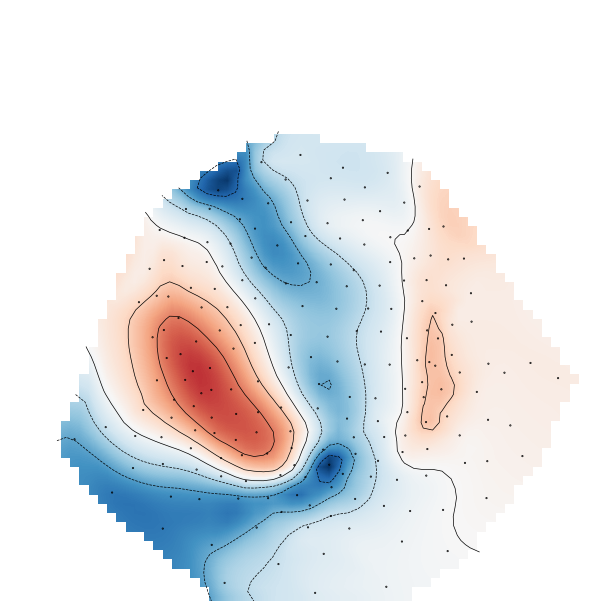

In [50]:
print(f"SNR topomap")
print(f"Minimum SNR: {np.min(snr)}")
print(f"Maximum SNR: {np.max(snr)}")
_ = mne.viz.plot_topomap(snr, data["eeg_coreg"].info, size=6, outlines=None, extrapolate="local")

#### Part 2: Uncertainty
🚨 Run cell '📦 imports' and '🧠 data' before continuing. 

Here we run the simulation multiple times for various patch locations and patch sizes.

#### 🛠️ <font color=violet>Select loop parameters</font>

In [65]:
rg_snr = [10, 11]     # range for EEG SNR
rg_spw = [0, 0.5]     # range of spreading weight
rg_spd = 50           # spreading delay
rep    = 1000         # number of repetition

#### Preparing data

In [63]:
# storage
target_snr = np.zeros(rep)                                     
true_snr   = np.zeros((rep, len(data["eeg_coreg"].ch_names)))

# vertno (to select dipole and instanciate mne.SourceEstimate)
vertno = [data["fwd_hr"]["src"][0]["vertno"], data["fwd_hr"]["src"][1]["vertno"]]

# dipole distance matrix (to grow dipole patch)
dist = [
    data["fwd_hr"]["src"][0]["dist"][vertno[0]][:,vertno[0]], 
    data["fwd_hr"]["src"][1]["dist"][vertno[1]][:,vertno[1]],
]

# signal for active dipoles
wavelet        = pywt.ContinuousWavelet("mexh")
[signal, time] = wavelet.wavefun(level=5, length=int(sfreq*duration))
signal         = signal*1e-8    # scale to nA

# covariance for background dipoles
I    = np.eye(len(data["sc_hr"]))
covb = np.linalg.inv((I-data["sc_hr"])) @ (I-data["sc_hr"])
covb = (covb + covb.T)/2

# estimated EEG average power originating from background dipoles
Pb   = np.diagonal(A @ covb @ A.T)

# functions to compute average power of EEGa and estimate variance
compute_Pa  = lambda Xa: np.diagonal(A @ np.cov(Xa) @ A.T)
compute_var = lambda snr, Pa, Pb: 10**(-snr/10) * Pa/Pb

#### ⚙️ **<font color=green>Loop through simulations</font>**

In [ ]:
for i in range(rep):
    # select state
    snr = np.random.uniform(rg_snr[0], rg_snr[1])
    r   = np.random.uniform(rg_r[0], rg_r[1])

    # generate patch
    starting_roi = np.random.choice(labels)
    roi_mask     = np.isin(labels, starting_roi)
    
    # active dipoles
    Xa = spread_signal(signal, roi_mask, data["sc_hr"], r)
    Pa = compute_Pa(Xa)

    # background dipoles
    idx = np.argmax(Pa)
    var = compute_var(snr, Pa[idx], Pb[idx])

    rng = np.random.default_rng()
    Xb  = rng.multivariate_normal(mean=np.zeros(len(covb)), cov=var*covb, size=int(sfreq*duration), method="cholesky").T

    # EEG SNR
    EEGa    = A @ Xa 
    EEGb    = A @ Xb 
    eeg_snr = mm.utils.compute_snr(EEGa, EEGb)

    # store variance and EEG SNR
    target_snr[i] = snr
    true_snr[i,:] = eeg_snr

#### 🌟 Visualize distributions

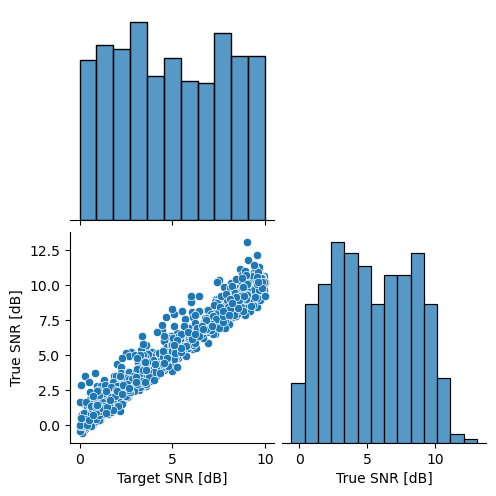

In [115]:
true_snr_max = np.max(true_snr, axis=1)
results      = pd.DataFrame({"True SNR [dB]":true_snr_max, "Target SNR [dB]":target_snr})

_  = sns.pairplot(
    results, 
    x_vars = ["Target SNR [dB]", "True SNR [dB]"],
    y_vars = ["Target SNR [dB]","True SNR [dB]"],
    corner = True,
)

## Section 3: Create Dataset
🚨 Run cell '📦 imports' and '🧠 data' before continuing.

#### Dataset Propreties

In [6]:
# data info
name      = "SNR 20, spreading 25%"                                   # name of dataset
folder    = Path(config["SIM_DIR"])/"sim-SNR20-spw25SAVEME"    # folder to save data
n_samples = 20                                                        # number of samples

# sample properties
#snr_range = [10,11]     # range for the EEG SNR
#spw_range = [0,0.25]    # range for spreading weight
spd       = 50          # spreading delay [ms]
duration  = 1           # duration in [s]
#noise_std = 1e-6
#brw_step  = 1e-10

#### Preparations ...

In [8]:
# check folder existence
if folder.exists():
    raise FileExistsError(f"\033[91mFolder '{folder}' already exists.")
else:
    folder.mkdir(parents=True)

N = data["fwd"]["nsource"]
M = data["eeg_coreg"].info["nchan"]
T = int(sfreq*duration)

# vertno (to select dipole and instanciate mne.SourceEstimate)
vertno = [data["fwd"]["src"][0]["vertno"], data["fwd"]["src"][1]["vertno"]]

# signal for active dipoles
wavelet        = pywt.ContinuousWavelet("mexh")
[signal, time] = wavelet.wavefun(level=5, length=T)

# shift delay
shift = int(spd/1000*sfreq)

# functions to compute average power of EEGa and estimate variance
compute_scaling = lambda snr, Ps, Pn: np.sqrt(10**(snr/10) * Pn / Ps)

# source locations
source_regions = mm.utils.select_sources(sub, mask=data["ctx_mask"], cras=data["cras"])
source_regions = data["parc"].label_points(source_regions)
source_regions = np.random.choice(source_regions, n_samples)

#### ⚙️ <font color=green>Generate dataset</font>

In [9]:
folder = Path(folder)

for i in range(n_samples):

    # select state
    snr      = 20
    r        = source_regions[i]

    eeg, gt, _, _ = mm.utils.simulate_EEG(data["eeg_coreg"].info, data["fwd"], labels, data["sc"], r, target_snr=snr, electric_noise=1e-9)

    # save simulation
    fsample = folder/f"sample{i+1}"
    fsample.mkdir()

    gt[0].save(fsample/f"{sub}_sample{i+1}_stc.fif", verbose="warning")
    eeg[0].save(fsample/f"{sub}_sample{i+1}_ave.fif", verbose="warning")


# create info file
text = f"""
    Name: {name} \n
    Subject: {sub} \n
    Duration: {duration} seconds [s]\n
    Sampling frequency: {sfreq} [Hz]\n
    """

with open(folder/"info.txt", "w") as file:
    file.write(text)